# Rebuttle for Case 1
- proof-of-concept: corsely resolved plume, sparse well measurement, damaged geo data
- plot contours, profiles, overall statistical metrics, posterior diversity in the main text, no sensivity analysis
- plot other sensivity analysis in the si

In [1]:
%env CUDA_VISIBLE_DEVICES = 4

import torch
import numpy as np
import h5py
import matplotlib.pyplot as plt
import seaborn as sns

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda")

# define my own color
from matplotlib.colors import LinearSegmentedColormap
import json
with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]
rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)
x = rgb_points[:, 0]
r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]
colors = list(zip(x, zip(r, g, b)))
mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)

env: CUDA_VISIBLE_DEVICES=4


## diffusion

In [25]:
u_net_model = create_model(image_size= 64,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4,2,1",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_unet_experiment1/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

loaded unet


In [26]:
operator =  get_operator(name='cartesian_sparse_measurement_all',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=5
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

Simulation data loaded, with shape (64, 64, 64, 3)


In [27]:
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='vanilla')    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")
sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

no_of_samples = 10
time_length = 64
latent_size = 256

In [28]:
x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Measurement shape: torch.Size([64, 5, 3])


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

...

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [29]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
# torch.save(gen_latents, 'conditional_outputs/pts/CNF_out_Unconditional_10.pt')

Generated latents shape: torch.Size([10, 64, 256])


## neural field

In [30]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [31]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Unconditional_10.pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


# **analysis**

In [2]:
gt = torch.from_numpy(np.load('../../../Dataset/Cartesian_all3_small.npy')[1998]).cpu()
superres_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution.pt', map_location='cpu')
sparse_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_sparse5.pt', map_location='cpu')
inpaint_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting.pt', map_location='cpu')
print(gt.shape, superres_pt.shape, sparse_pt.shape, inpaint_pt.shape)


superres_low_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution-4.pt', map_location='cpu')
sparse_low_pt = torch.load('conditional_outputs/pts/CNF_out_Cart1Sparse_All.pt', map_location='cpu')
inpaint_low_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting-25%.pt', map_location='cpu')

superres_high_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution-16.pt', map_location='cpu')
sparse_high_pt = torch.load('conditional_outputs/pts/CNF_out_Cart20Sparse_All.pt', map_location='cpu')
inpaint_high_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting-75%.pt', map_location='cpu')

torch.Size([64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3])


In [3]:
def get_mean_std(input):
    mean = torch.mean(input, dim=0)
    std = torch.std(input, dim=0)
    return mean, std

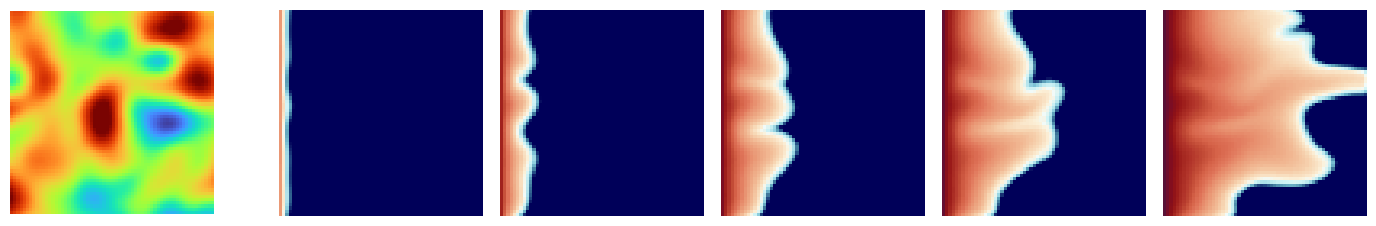

In [8]:
def make_gt_1x3(figsize=(18, 3), width_space=0.25, height_space=0.0):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(1, 7, width_ratios=[1, 0.15, 1, 1, 1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    ax = fig.add_subplot(gs[0])
    ax.set_aspect('equal')
    ax.axis('off')
    axes.append(ax)
    for col in range(2, 7):
        ax = fig.add_subplot(gs[col])
        ax.set_aspect('equal')
        ax.axis('off')
        axes.append(ax)
    
    return fig, axes

def make_gt_1x6_contour(gt_tensor, figsize=(18, 3), width_space=0.25, height_space=0.0):
    fig, axes = make_gt_1x3(figsize=figsize, width_space=width_space, height_space=height_space)

    ts = [3, 12, 25, 38, 63]

    axes[0].imshow(gt_tensor[:, ..., -1].mean(dim=0), vmin=1.5, vmax=6.5, cmap='turbo')

    for i, ts in enumerate(ts):
        axes[i+1].imshow(gt_tensor[ts, :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)
    
    return fig, axes

fig, axes = make_gt_1x6_contour(gt, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/gt_contour.pdf', bbox_inches='tight')

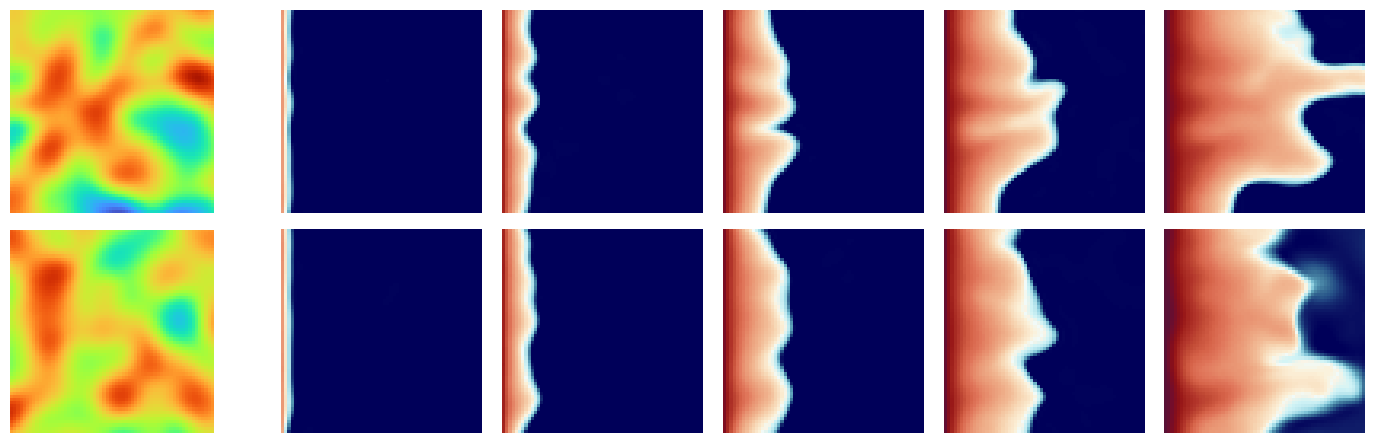

In [15]:
def make_2x6(figsize=(18, 6), width_space=0.25, height_space=0.2):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(2, 7, width_ratios=[1, 0.15, 1, 1, 1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    for row in range(2):
        row_axes = []
        ax = fig.add_subplot(gs[row, 0])
        ax.set_aspect('equal')
        ax.axis('off')
        row_axes.append(ax)
        for col in range(2, 7):
            ax = fig.add_subplot(gs[row, col])
            ax.set_aspect('equal')
            ax.axis('off')
            row_axes.append(ax)
        axes.append(row_axes)
    
    return fig, axes

def make_2x6_contour(generated_tensor, generated_tensor2, show_idx=0, figsize=(18, 6), width_space=0.25, height_space=0.2):
    fig, axes = make_2x6(figsize=figsize, width_space=width_space, height_space=height_space)



    ts = [3, 12, 25, 38, 63]

    axes[0][0].imshow(generated_tensor[show_idx, :, ..., -1].mean(dim=0), vmin=1.5, vmax=6.5, cmap='turbo')
    axes[1][0].imshow(generated_tensor2[show_idx, :, ..., -1].mean(dim=0), vmin=1.5, vmax=6.5, cmap='turbo')

    for i, ts in enumerate(ts):
        axes[0][i+1].imshow(generated_tensor[show_idx, ts, :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)
        axes[1][i+1].imshow(generated_tensor2[show_idx, ts, :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)

    return fig, axes

fig, axes = make_2x6_contour(superres_high_pt, superres_low_pt, show_idx=7, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/superres_contour.pdf', bbox_inches='tight')

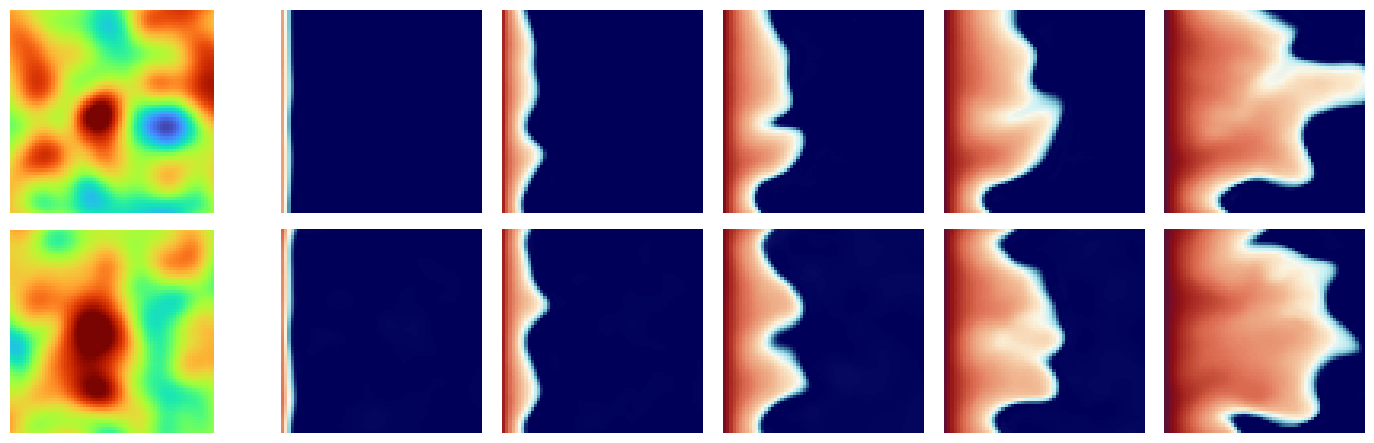

In [16]:
fig, axes = make_2x6_contour(sparse_high_pt, sparse_low_pt, show_idx=4, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08) #1
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/sparse_contour.pdf', bbox_inches='tight')

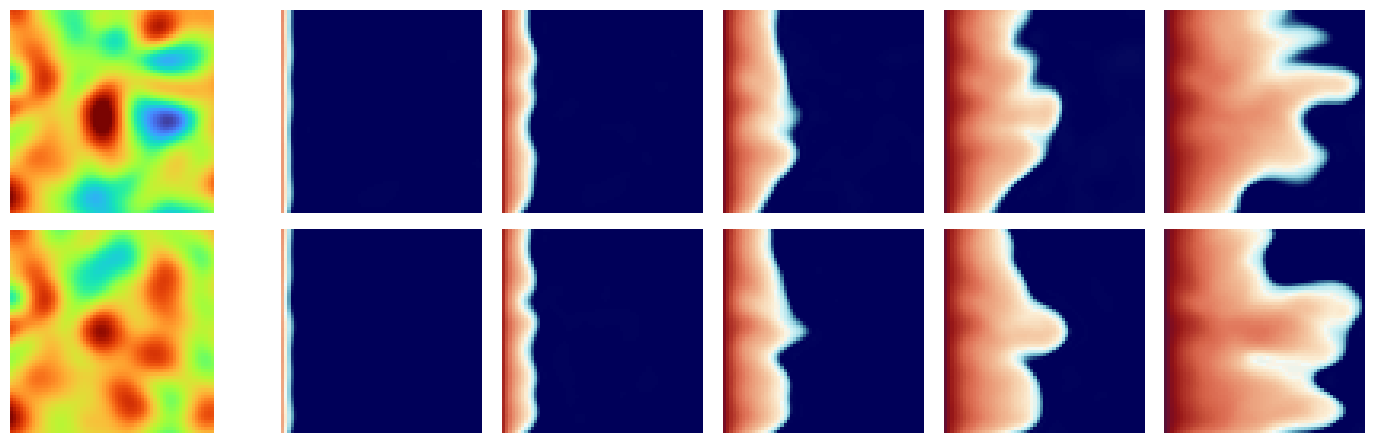

In [23]:
fig, axes = make_2x6_contour(inpaint_high_pt, inpaint_low_pt, show_idx=0, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/inpaint_contour.pdf', bbox_inches='tight')

torch.Size([1, 64, 16, 16])


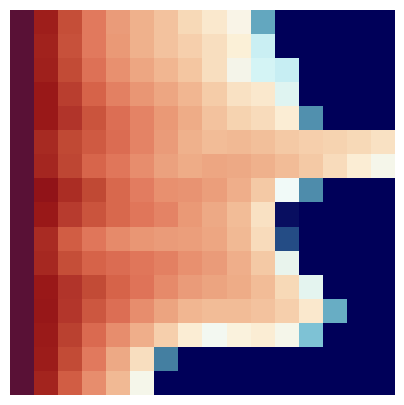

In [14]:
import torch.nn.functional as F

downsampled = F.interpolate(gt[:, :, :, 1].unsqueeze(0), size=(16, 16), mode='nearest')
print(downsampled.shape)

plt.figure(figsize=(5, 5))

plt.imshow(downsampled[0, -1], vmin=0, vmax=0.6, cmap=mycmap)
ax = plt.gca()
ax.set_aspect('equal')
plt.axis('off')
plt.savefig('conditional_outputs/[rebuttle]figs-for-SI/superres_condition_4x.pdf', bbox_inches='tight')

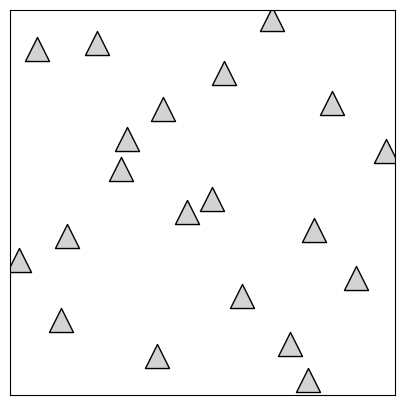

In [ ]:
# pts = [(32, 28)]
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')

plt.figure(figsize=(5, 5))
plt.imshow(np.full((64, 64), np.nan), cmap="Greys", alpha=0)
for y, x in pts:
    plt.scatter(x, y, color='lightgray', marker='^', s=300, edgecolors='k')
ax = plt.gca()
ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
plt.savefig('conditional_outputs/[rebuttle]figs-for-SI/sparse_condition_20well.pdf', bbox_inches='tight')

53 50


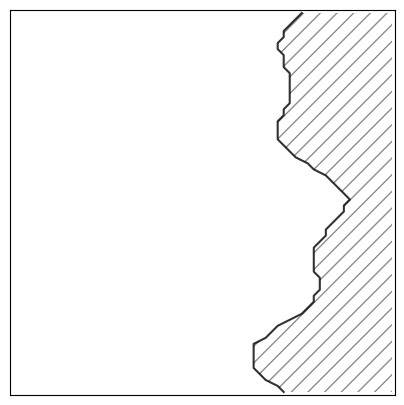

In [10]:
from matplotlib.path import Path
import matplotlib.patches as patches

def generate_boundary_mask(h, w, boundary_x=40, perturbation_amplitude=8, n_modes=5, seed=42):
    rng = np.random.RandomState(seed)
    mask_np = np.ones((h, w), dtype=np.float32)
    rows = np.arange(h)
    t = rows / h * 2 * np.pi
    perturbation = np.zeros(h)
    for _ in range(n_modes):
        freq = rng.uniform(1, 4)
        amplitude = rng.uniform(0.3, 1.0)
        phase = rng.uniform(0, 2 * np.pi)
        perturbation += amplitude * np.sin(freq * t + phase)
    if perturbation.max() - perturbation.min() > 0:
        perturbation = 2 * (perturbation - perturbation.min()) / (perturbation.max() - perturbation.min()) - 1
    perturbation *= perturbation_amplitude
    boundary = boundary_x + perturbation
    boundary = np.clip(boundary, 1, w - 1).astype(int)
    for i in range(h):
        mask_np[i, boundary[i]:] = 0.0
    n_masked = (mask_np == 0).sum()
    return mask_np, n_masked, boundary

mask, n_masked, boundary = generate_boundary_mask(64, 64, boundary_x=48, perturbation_amplitude=8, n_modes=6, seed=55)

plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap='gray', alpha=0)
plt.plot(boundary, np.arange(64), 'k', linewidth=1.5, alpha=0.8)
 
# 构建 mask 区域的多边形（boundary 右侧到图像右边缘）
verts = []
for i in range(64):
    verts.append((boundary[i], i))
verts.append((63, 63))  # 右下角
verts.append((63, 0))   # 右上角
verts.append((boundary[0], 0))  # 闭合回起点
 
codes = [Path.MOVETO] + [Path.LINETO] * (len(verts) - 2) + [Path.CLOSEPOLY]
 
patch = patches.PathPatch(
    Path(verts, codes),
    facecolor='none',
    edgecolor='gray',
    hatch='//',
    linewidth=0,
    alpha=0.9
)
 
ax = plt.gca()
ax.add_patch(patch)
ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
print(boundary[28], boundary[26])

plt.savefig('conditional_outputs/[rebuttle]figs-for-SI/inpaint_condition_75%.pdf', bbox_inches='tight')

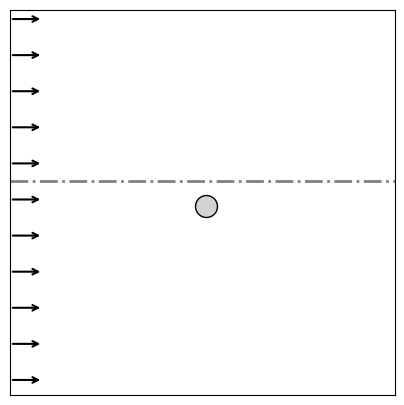

In [423]:
plt.figure(figsize=(5, 5))
ax = plt.gca()
plt.imshow(np.full((64, 64), np.nan), cmap="Greys", alpha=0)

plt.axhline(y=28, ls='-.', lw=2, c='gray')
plt.scatter(32, 32, s=250, c='lightgray', marker='o', edgecolors='k', zorder=100)
for y in np.arange(1, 64, 6):
    ax.annotate('', xy=(5, y), xytext=(-0.5, y),
                arrowprops=dict(arrowstyle='->', color='k', lw=1.5))


ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
plt.savefig('conditional_outputs/[rebuttle]figs/gt_condition.pdf', bbox_inches='tight')

## well residuals

In [3]:
query_points = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]

gene_well_records = []
gt_well_records = []



for (x, y) in query_points:
    gene_well_t_records = []
    gt_well_t_records = []
    for t in range(64):
        gt_well_t_records.append(gt[t, x, y, :].cpu().numpy())
        gene_well_t_records.append(sparse_pt[:, t, x, y, :].cpu().numpy())
    gene_well_records.append(np.array(gene_well_t_records))
    gt_well_records.append(np.array(gt_well_t_records))


# print(len(gene_well_records), len(gt_well_records))
# print(len(gene_well_records[0]), len(gt_well_records[0]))
# print(len(gene_well_records[0][0]), len(gt_well_records[0][0]))
# print(len(gene_well_records[0][0][0]), len(gt_well_records[0][0]))

gene_well_records = np.array(gene_well_records)
gt_well_records = np.array(gt_well_records)
print(gene_well_records.shape, gt_well_records.shape)

(5, 64, 10, 3) (5, 64, 3)


In [37]:
def plot_k_and_time_series(gene_list, gt_list, well_num, a, b, c, d):
    gene_well = gene_list[well_num]
    gt_well = gt_list[well_num]
    
    gene_K = gene_well[:, :, -1].mean(axis=0)
    gene_S = gene_well[:, :, 1]
    gene_P = gene_well[:, :, 0]
    
    gt_K = gt_well[:, -1].mean(axis=0)
    gt_S = gt_well[:, 1]
    gt_P = gt_well[:, 0]
    
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    # im0 = axs[0].bar(['Generated', 'Ground Truth'], [gene_K.mean(), gt_K], yerr=[gene_K.std(), 0], capsize=10, color=['lightblue', 'salmon'])
    
    axs[0].bar(['Generation'], [gene_K.mean()], yerr=[gene_K.std()], capsize=10, color=['lightblue'], width=0.4)
    axs[0].bar(['Reference'], [gt_K], color=['salmon'], width=0.4)
    residual = np.abs(gene_K.mean() - gt_K)
    axs[0].text(
    0.4, 0.7,
    f'Residual:\n{residual:.4f}',
    transform=axs[0].transAxes,
    ha='left', va='top', fontsize=12
    )
    axs[0].set_title('Permeability at well ' + str(well_num+1))
    axs[0].set_ylabel('$Log(K)$ (mD)')
    
    im1 = axs[1].plot(gene_S.mean(axis=1), label='Generation', color='blue')
    axs[1].fill_between(np.arange(gene_S.shape[0]), gene_S.mean(axis=1) - gene_S.std(axis=1), gene_S.mean(axis=1) + gene_S.std(axis=1), color='lightblue', alpha=0.5)
    im1 = axs[1].plot(gt_S, label='Reference', color='red')
    sat_residual = np.mean(np.abs(gene_S.mean(axis=1) - gt_S))
    axs[1].text(
    a, b,
    f'Average residual:\n{sat_residual:.4f}',
    transform=axs[1].transAxes,
    ha='left', va='top', fontsize=12
    )
    axs[1].set_title('Saturation at well ' + str(well_num+1))
    axs[1].set_ylabel('$S_g$')
    axs[1].set_xlabel('Time step')
    axs[1].legend()
    
    im2 = axs[2].plot(gene_P.mean(axis=1), label='Generation', color='blue')
    axs[2].fill_between(np.arange(gene_P.shape[0]), gene_P.mean(axis=1) - gene_P.std(axis=1), gene_P.mean(axis=1) + gene_P.std(axis=1), color='lightblue', alpha=0.5)
    im2 = axs[2].plot(gt_P, label='Reference', color='red')
    pre_residual = np.mean(np.abs(gene_P.mean(axis=1) - gt_P))
    axs[2].text(
    c, d,
    f'Average residual:\n{pre_residual:.4e}',
    transform=axs[2].transAxes,
    ha='left', va='top', fontsize=12
    )
    axs[2].set_title('Pressure at well ' + 
                     str(well_num+1))
    axs[2].set_ylabel('$P$ (Pa)')
    axs[2].set_xlabel('Time step')
    axs[2].legend()
    

    return fig

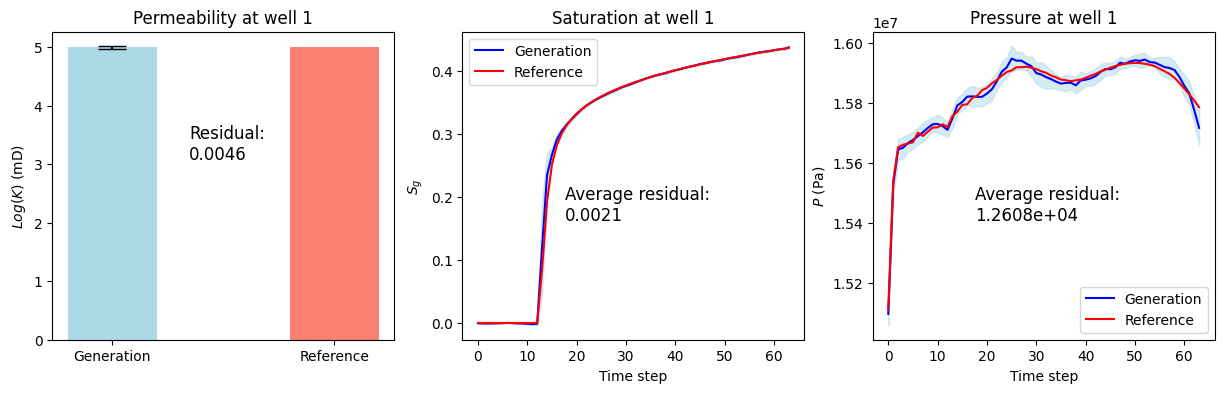

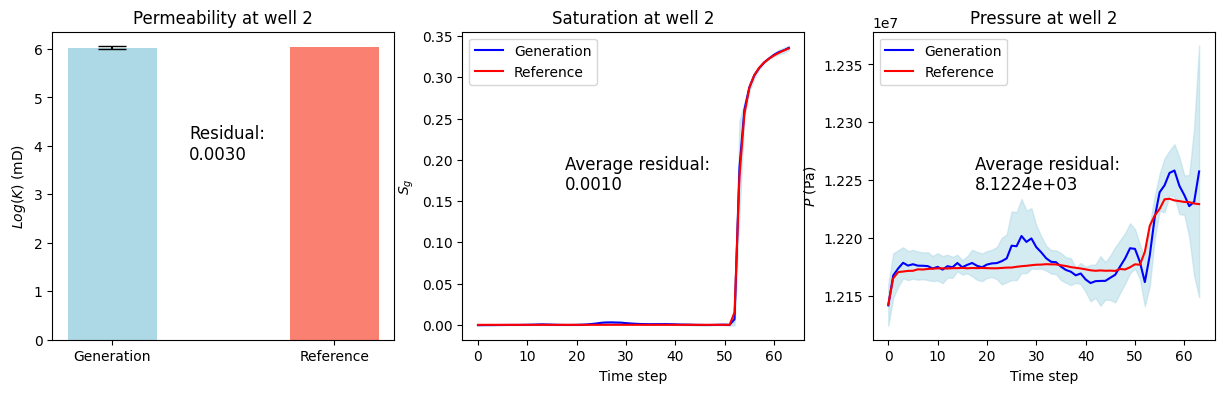

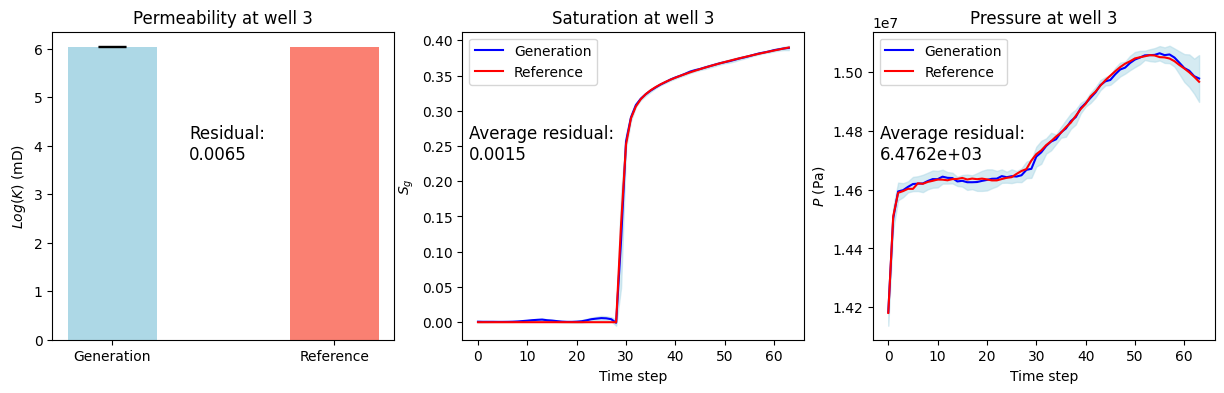

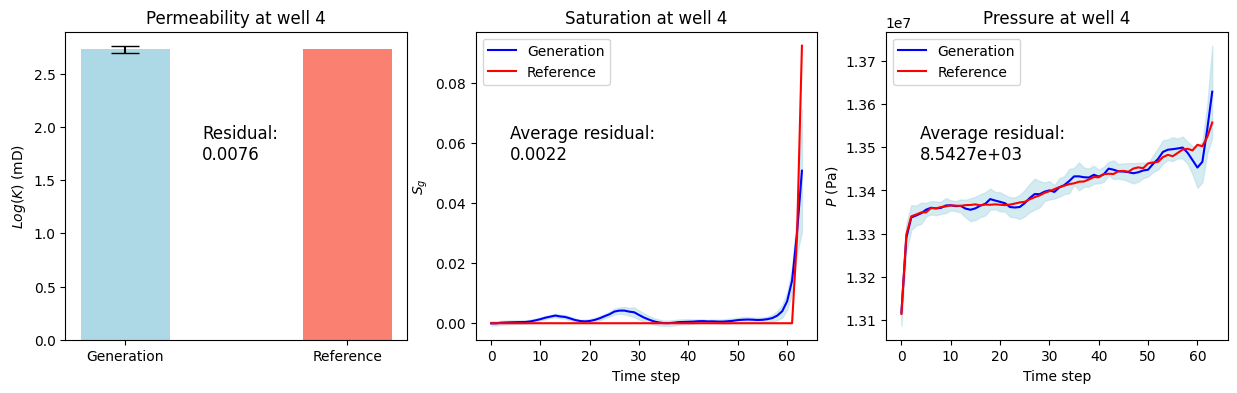

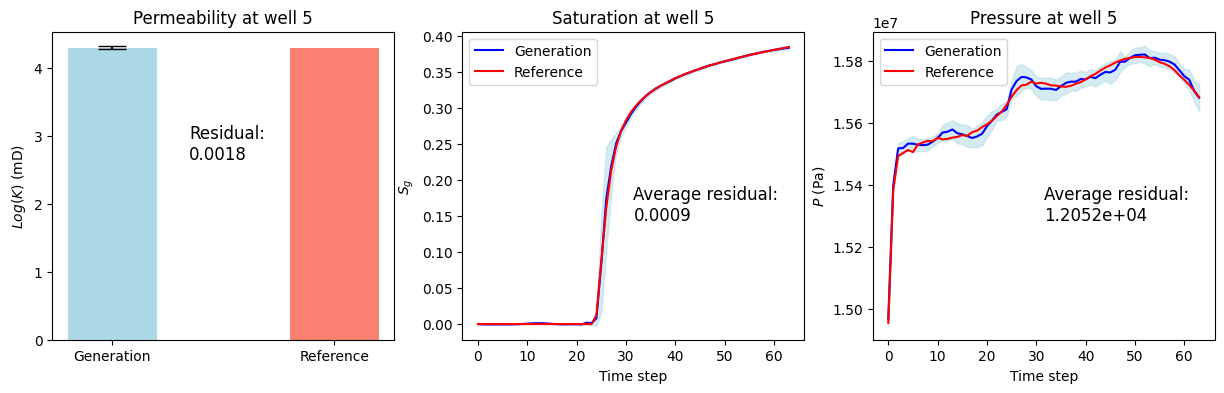

In [38]:
fig = plot_k_and_time_series(gene_well_records, gt_well_records, well_num=0, a=0.3, b=0.5, c=0.3, d=0.5)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/well1_time_series.pdf', bbox_inches='tight')

fig = plot_k_and_time_series(gene_well_records, gt_well_records, well_num=1, a=0.3, b=0.6, c=0.3, d=0.6)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/well2_time_series.pdf', bbox_inches='tight')

fig = plot_k_and_time_series(gene_well_records, gt_well_records, well_num=2, a=0.02, b=0.7, c=0.02, d=0.7)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/well3_time_series.pdf', bbox_inches='tight')

fig = plot_k_and_time_series(gene_well_records, gt_well_records, well_num=3, a=0.1, b=0.7, c=0.1, d=0.7)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/well4_time_series.pdf', bbox_inches='tight')

fig = plot_k_and_time_series(gene_well_records, gt_well_records, well_num=4, a=0.5, b=0.5, c=0.5, d=0.5)
fig.savefig('conditional_outputs/[rebuttle]figs-for-SI/well5_time_series.pdf', bbox_inches='tight')